<a href="https://colab.research.google.com/github/AthyaNivedita/AIML/blob/main/aiml2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive (2).zip


In [ ]:
import zipfile

zip_file = "archive.zip"

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall("archive")

In [ ]:
import os

os.listdir("archive")

['student-lifestyle-and-stress-dataset.csv']

In [ ]:
import zipfile

with zipfile.ZipFile("archive.zip", "r") as zip_ref:
    zip_ref.extractall("dataset")

print("Extraction Complete")

Extraction Complete


In [ ]:
df = pd.read_csv("dataset/student-lifestyle-and-stress-dataset.csv")

df.head()

,Student_Type,Sleep_Hours,Study_Hours,Social_Media_Hours,Attendance,Exam_Pressure,Family_Support,Month,Stress_Level
0,school,6.868702,1.711722,3.176942,NaN,8.0,7.0,2.0,1
1,school,8.519088,3.251084,3.880787,93.978465,6.0,4.0,3.0,1
2,college,4.498770,6.306885,2.936172,64.421253,7.0,1.0,12.0,1
3,school,8.591223,2.384922,5.222832,81.868960,2.0,7.0,7.0,0
4,college,5.329293,9.345179,7.815869,85.847982,5.0,6.0,10.0,1


In [ ]:
print(df.info())

print(df.describe())

print(df.columns)

print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25500 entries, 0 to 25499
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Student_Type        24248 non-null  object 
 1   Sleep_Hours         24167 non-null  float64
 2   Study_Hours         24223 non-null  float64
 3   Social_Media_Hours  24188 non-null  float64
 4   Attendance          24195 non-null  float64
 5   Exam_Pressure       24230 non-null  float64
 6   Family_Support      24209 non-null  float64
 7   Month               24186 non-null  float64
 8   Stress_Level        25500 non-null  int64  
dtypes: float64(7), int64(1), object(1)
memory usage: 1.8+ MB
None
        Sleep_Hours   Study_Hours  Social_Media_Hours    Attendance  \
count  24167.000000  24223.000000        24188.000000  24195.000000   
mean       6.458948      4.696477            3.555614     81.270961   
std        1.504228      2.240148            1.901528     12.052045   
mi

In [ ]:
df = pd.get_dummies(df, drop_first=True)
X = df[['Study_Hours']]

y = df['Stress_Level']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
print(df.isnull().sum())

Sleep_Hours                     1333
Study_Hours                     1277
Social_Media_Hours              1312
Attendance                      1305
Exam_Pressure                   1270
Family_Support                  1291
Month                           1314
Stress_Level                       0
Student_Type_school                0
Student_Type_working_student       0
dtype: int64


In [ ]:
X = X.fillna(X.mean())

In [ ]:
y = y.fillna(y.mean())

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [ ]:
multiple_model = LinearRegression()

multiple_model.fit(X_train, y_train)

LinearRegression()

In [ ]:
y_pred = multiple_model.predict(X_test)

In [ ]:
print("Mean Absolute Error :", mean_absolute_error(y_test, y_pred))

print("Mean Squared Error :", mean_squared_error(y_test, y_pred))

print("Root Mean Squared Error :", np.sqrt(mean_squared_error(y_test, y_pred)))

print("R2 Score :", r2_score(y_test, y_pred))

Mean Absolute Error : 0.4033339855436972
Mean Squared Error : 0.20157644159495067
Root Mean Squared Error : 0.44897265127728064
R2 Score : 0.048883986614965624


In [ ]:
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': multiple_model.coef_
})

print(coefficients)

       Feature  Coefficient
0  Study_Hours     0.043614


In [ ]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

comparison.head(15)

,Actual,Predicted
6913,0,0.175985
11124,1,0.250594
25100,0,0.199655
2764,1,0.374321
23216,0,0.228036
17269,0,0.201799
3073,0,0.213666
8184,1,0.374453
2595,1,0.253965
5483,0,0.289421


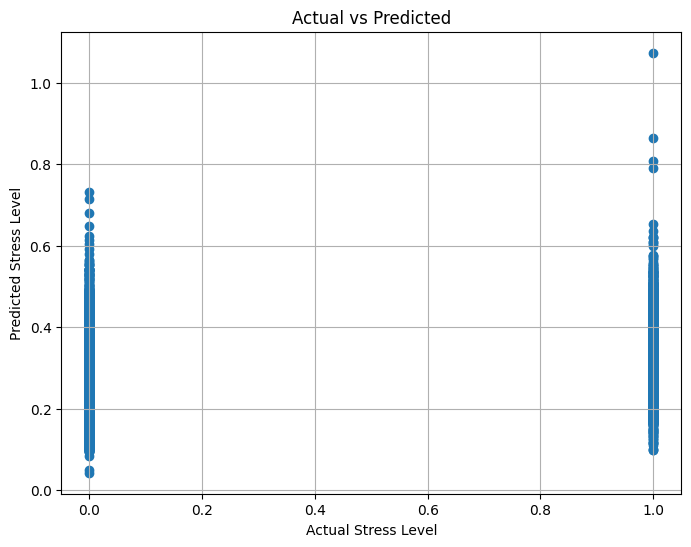

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Stress Level")

plt.ylabel("Predicted Stress Level")

plt.title("Actual vs Predicted")

plt.grid(True)

plt.show()

In [ ]:
comparison.to_csv("Stress_Predictions.csv", index=False)

print("Predictions saved successfully.")

Predictions saved successfully.


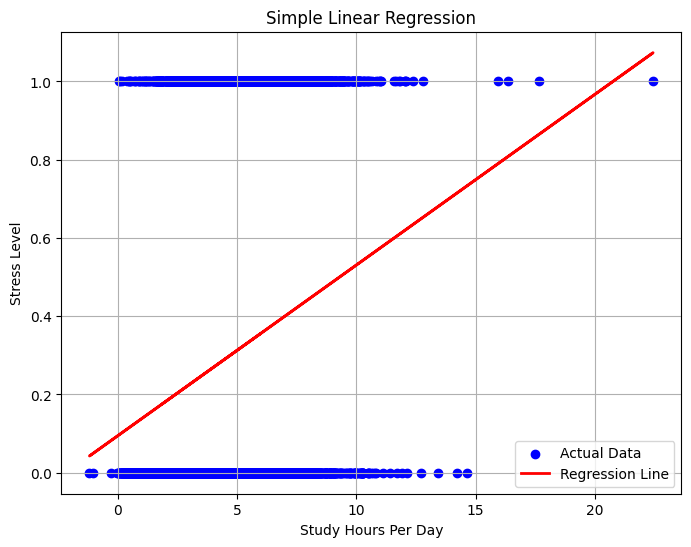

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(X_test, y_test,
            color='blue',
            label='Actual Data')

plt.plot(X_test, y_pred,
         color='red',
         linewidth=2,
         label='Regression Line')

plt.title("Simple Linear Regression")
plt.xlabel("Study Hours Per Day")
plt.ylabel("Stress Level")
plt.legend()
plt.grid(True)

plt.show()

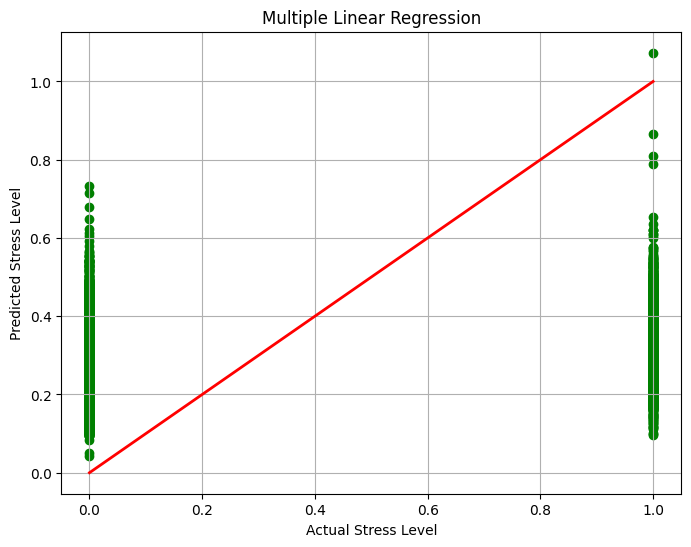

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(y_test,
            y_pred,
            color='green')

plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color='red',
         linewidth=2)

plt.title("Multiple Linear Regression")
plt.xlabel("Actual Stress Level")
plt.ylabel("Predicted Stress Level")

plt.grid(True)

plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# For reproducible results
np.random.seed(42)

# Generate study hours
study_hours = np.random.randint(1, 11, 100)

# Generate stress level with some noise
stress_level = 2 * study_hours + 5 + np.random.normal(0, 2, 100)

synthetic_df = pd.DataFrame({
    "Study_Hours_Per_Day": study_hours,
    "Stress_Level": stress_level
})

synthetic_df.head()

,Study_Hours_Per_Day,Stress_Level
0,7,17.207330
1,4,12.776024
2,8,23.937883
3,5,12.752203
4,7,20.900011


In [ ]:
X = synthetic_df[['Study_Hours_Per_Day']]
y = synthetic_df['Stress_Level']

model = LinearRegression()
model.fit(X, y)

predictions = model.predict(X)

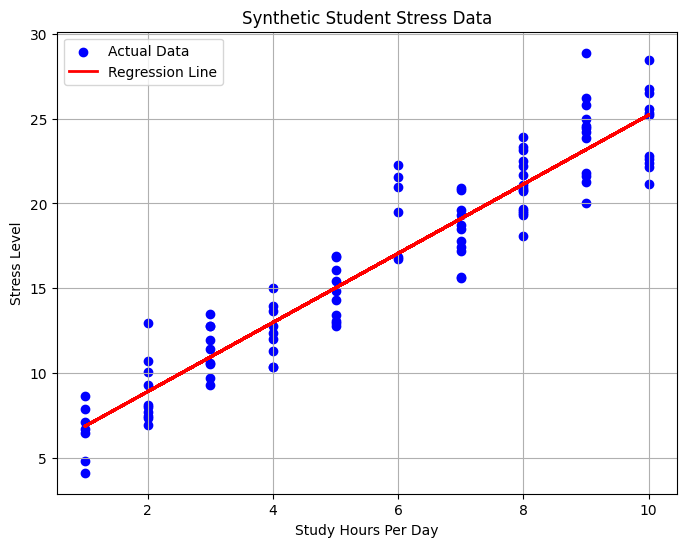

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    X,
    y,
    color="blue",
    label="Actual Data"
)

plt.plot(
    X,
    predictions,
    color="red",
    linewidth=2,
    label="Regression Line"
)

plt.title("Synthetic Student Stress Data")
plt.xlabel("Study Hours Per Day")
plt.ylabel("Stress Level")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
np.random.seed(42)

n = 200

study = np.random.randint(1, 11, n)
sleep = np.random.randint(4, 10, n)
exercise = np.random.randint(0, 3, n)
social = np.random.randint(1, 6, n)

stress = (
    2 * study
    - 1.5 * sleep
    - 1 * exercise
    - 0.5 * social
    + 10
    + np.random.normal(0, 2, n)
)

df = pd.DataFrame({
    "Study_Hours_Per_Day": study,
    "Sleep_Hours_Per_Day": sleep,
    "Physical_Activity_Hours_Per_Day": exercise,
    "Social_Hours_Per_Day": social,
    "Stress_Level": stress
})

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X = df[[
    "Study_Hours_Per_Day",
    "Sleep_Hours_Per_Day",
    "Physical_Activity_Hours_Per_Day",
    "Social_Hours_Per_Day"
]]

y = df["Stress_Level"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

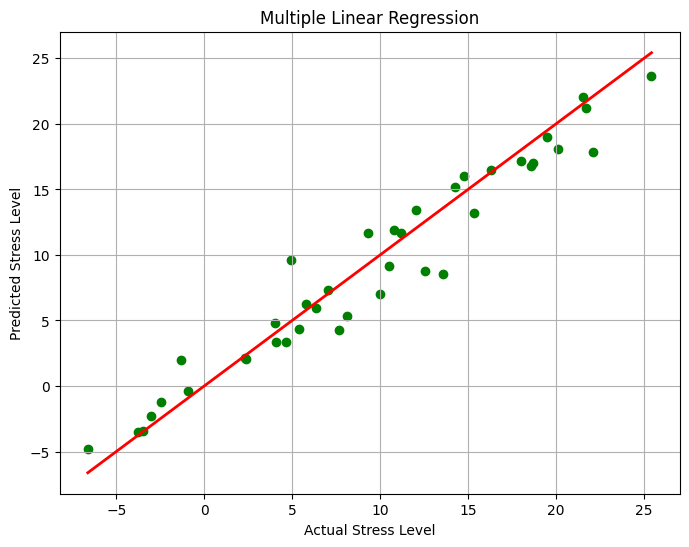

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    y_test,
    y_pred,
    color="green"
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linewidth=2
)

plt.xlabel("Actual Stress Level")
plt.ylabel("Predicted Stress Level")
plt.title("Multiple Linear Regression")

plt.grid(True)

plt.show()